# Projekt - fáza č. 3

In [3]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, TargetEncoder, StandardScaler,
                                   PowerTransformer, KBinsDiscretizer)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay, classification_report)
sns.set_theme(style="whitegrid")

## Príprava dát (toto je prevzaté z fázy 2)

Fáza 3 je v samostatnom notebooku, preto tu bez zmeny opakujeme čistenie a predspracovanie z fázy 2, aby bol notebook vykonateľný sám osebe:

* delenie 80/20 podľa jednotiek (`id_unit`), stratifikované na `Failure`, `random_state = 42` - rovnaké delenie ako vo fáze 2,
* čistenie a zlúčenie troch tabuliek (`make_numeric_frame`),
* pipeline z 2.3: one-hot, target encoding depa, orezanie 1,5 x IQR -> medián -> Yeo-Johnson -> StandardScaler a výber 16 atribútov z 2.2.

Všetko, čo sa učí z dát, je v `sklearn` pipeline, takže sa učí iba na trénovacej časti (aj vnútri krížovej validácie).

Dátové súbory sa načítajú z priečinka `data` v pracovnom adresári. Pri spustení z iného umiestnenia možno priečinok s CSV súbormi nastaviť cez premennú prostredia `IAU_DATA_DIR`.

In [4]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
DATA_DIR = Path(os.environ.get("IAU_DATA_DIR", "data"))

def parse_dates(col):
    s = pd.Series(col).astype(str).str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d", "%Y/%m/%d", "%d %b %Y", "%m/%d/%Y, %H:%M:%S", "%Y-%m-%d %H:%M:%S"]:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

def clean_gateways(df):
    df = df.copy().rename(columns={"Lon": "lon", "idDepot": "id_deport", "macAddress": "mac_addr",
                                   "versionFirmware": "version_firmware", "Vendor": "vendor",
                                   "Technician": "technician"})
    if "gateway_id" not in df.columns:
        df = df.reset_index()
    df["gateway_id"] = pd.to_numeric(df["gateway_id"].astype(str).str.replace(r"\D", "", regex=True),
                                     errors="coerce").astype("Int64")
    df["id_unit"] = pd.to_numeric(df["id_unit"], errors="coerce").astype("Int64")
    for c in ["install_date", "seen_last"]:
        df[c] = parse_dates(df[c])
    return df

def clean_readings(df):
    df = df.copy().rename(columns={"currentMotor": "curr_motor", "oilTemperature": "oil_temp",
                                   "pressure_reservoir": "press_reserv", "rmsVibration": "rms_vibration",
                                   "Flowmeter": "flow", "dischargeDewpoint": "dis_dewp", "Failure": "fail"})
    df["id_unit"] = pd.to_numeric(df["id_unit"].astype(str).str.strip().str.replace(r"\D", "", regex=True),
                                  errors="coerce")
    bad = df["id_unit"] > 2000                      # chybne id v tvare 90000 + skutocne id
    df.loc[bad, "id_unit"] = df.loc[bad, "id_unit"] - 90000
    df["id_unit"] = df["id_unit"].astype("Int64")
    df["cycle_ts"] = parse_dates(df["cycle_ts"])
    for col, bad_value in {"oil_temp": -999, "curr_motor": 99, "dp_filter": 120}.items():
        df[col] = df[col].replace(bad_value, np.nan)   # chybove kody senzorov
    sensor_cols = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp"]
    agg = {c: "mean" for c in sensor_cols}
    agg["fail"] = "max"
    return df.groupby(["id_unit", "cycle_ts"], as_index=False).agg(agg)   # duplicity jednotka + den

def clean_units(df):
    df = df.copy().rename(columns={"idDepot": "id_deport", "year_commission": "y_commission",
                                   "serviceHours": "serv_hours", "serial_number": "serial_num"})
    class_map = {"1": 1, "l": 1, "light": 1, "2": 2, "med": 2, "n": 2, "normal": 2,
                 "3": 3, "h": 3, "heavy": 3}
    df["duty_class"] = df["duty_class"].astype(str).str.strip().str.lower().map(class_map).astype("Int64")
    df["overhaul_last"] = parse_dates(df["overhaul_last"])
    df["serv_hours"] = pd.to_numeric(df["serv_hours"], errors="coerce")
    return df

gateways_c = clean_gateways(pd.read_csv(DATA_DIR / "gateways.csv", sep=";", index_col=13))
units_c = clean_units(pd.read_csv(DATA_DIR / "units.csv", sep=",", index_col=5))
gateways_c = gateways_c.dropna(subset=["id_unit"]).drop_duplicates("id_unit").drop(columns="id_deport")
gateways_c["id_unit"] = gateways_c["id_unit"].astype("int64")

CAT_COLS = ["hardware_model", "version_firmware"]
DROP_COLS = ["gateway_id", "mac_addr", "ipv4", "serial_num", "install_date", "seen_last",
             "overhaul_last", "cycle_ts", "vendor", "technician"]

def make_numeric_frame(readings_raw):
    r = clean_readings(readings_raw)
    df = (r.merge(units_c, on="id_unit", how="left", validate="m:1")
           .merge(gateways_c, on="id_unit", how="left", validate="m:1"))
    assert len(df) == len(r), "merge zmenil pocet riadkov"
    t = df["cycle_ts"]
    df["days_since_install"] = (t - df["install_date"]).dt.days
    df["days_since_overhaul"] = (t - df["overhaul_last"]).dt.days
    df["unit_age_years"] = t.dt.year - df["y_commission"]
    df["cycle_month"] = t.dt.month
    df["cycle_dow"] = t.dt.dayofweek
    df["cycle_doy"] = t.dt.dayofyear
    df["seen_before_install"] = (df["seen_last"] < df["install_date"]).astype(int)
    for c in ["dp_filter", "rms_vibration"]:
        df[c + "_missing"] = df[c].isna().astype(int)
    df = df.drop(columns=DROP_COLS)
    for c in df.columns:
        if str(df[c].dtype) in ("Int64", "Float64"):
            df[c] = df[c].astype("float64")
    return df

def prepare_data(readings_raw):
    df = make_numeric_frame(readings_raw)
    return df.drop(columns=["fail", "id_unit"]), df["fail"], df["id_unit"]

In [5]:
# spojite atributy (uprava v pipeline) a 16 atributov vybranych v 2.2
spojite = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp",
           "serv_hours", "signal_dbm", "lat", "lon", "days_since_install", "days_since_overhaul",
           "unit_age_years"]
selected_final = ["dp_filter_missing", "rms_vibration_missing", "duty_class", "dp_filter", "serv_hours",
                  "curr_motor", "rms_vibration", "dis_dewp", "press_reserv", "version_firmware_v3.4.1",
                  "y_commission", "oil_temp", "flow", "version_firmware_v2.7.0", "lat", "id_deport"]

class OutlierClipper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        X = np.asarray(X, dtype=float)
        q25, q75 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        self.lo_, self.hi_ = q25 - 1.5 * (q75 - q25), q75 + 1.5 * (q75 - q25)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)

class ColumnSelector(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        self.columns_ = list(self.columns)
        return self
    def transform(self, X):
        return X[self.columns]
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns, dtype=object)

def build_pipeline(vyber=selected_final):
    continuous_steps = Pipeline([
        ("clip", OutlierClipper()),
        ("impute", SimpleImputer(strategy="median")),
        ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scale", StandardScaler()),
    ])
    transform_all = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.05,
                                 sparse_output=False), CAT_COLS),
        ("depot", TargetEncoder(target_type="binary", smooth="auto",
                                cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)),
         ["id_deport"]),
        ("continuous", continuous_steps, spojite),
    ], remainder="passthrough", verbose_feature_names_out=False)
    kroky = [("transform", transform_all)]
    if vyber is not None:                       # vyber=None ponecha vsetky atributy (pouzijeme pri kontrole uniku)
        kroky.append(("select", ColumnSelector(vyber)))
    return Pipeline(kroky).set_output(transform="pandas")

In [6]:
data = pd.read_csv(DATA_DIR / "readings.csv", sep="\t")
jednotka = data["id_unit"].str[1:].astype(int)
jednotka = jednotka.where(jednotka <= 2000, jednotka - 90000)

sgkf = StratifiedGroupKFold(n_splits=round(1 / TEST_SIZE), shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(data, data["Failure"], groups=jednotka))

train_X, train_y, train_groups = prepare_data(data.iloc[train_idx])
test_X, test_y, test_groups = prepare_data(data.iloc[test_idx])

assert set(train_groups).isdisjoint(test_groups)
for nazov, X_, y_, g_ in [("train", train_X, train_y, train_groups), ("test", test_X, test_y, test_groups)]:
    print(nazov, "- riadky:", len(X_), "- jednotky:", g_.nunique(), "- podiel fail=1:", round(y_.mean(), 4))

train - riadky: 11016 - jednotky: 1597 - podiel fail=1: 0.1198
test - riadky: 2756 - jednotky: 402 - podiel fail=1: 0.1187


Dostali sme rovnaké množiny ako vo fáze 2 (11 016 trénovacích a 2 756 testovacích riadkov, podiel porúch asi 12 %). Testovaciu množinu odkladáme a použijeme ju až na záverečné overenie. Všetky rozhodnutia robíme iba na trénovacej množine pomocou krížovej validácie.

## 3.1 Jednoduchý klasifikátor na základe závislosti v dátach

### Implementácia ID3

ID3 stavia strom zhora nadol. V každom uzle vyberie atribút s najvyšším **informačným ziskom**, teda ten, ktorý najviac zníži entropiu cieľovej premennej.

Uzol sa rozvetví podľa hodnôt atribútu a ten sa na ceste od koreňa už nepoužije. Vetvenie končí, keď je uzol čistý, nie sú atribúty alebo žiadny nemá kladný zisk. List predikuje väčšinovú triedu.

**Rozhodnutia pri implementácii**

* Spojité atribúty delíme na **kvartily** (Q1 až Q4, `KBinsDiscretizer`). Hranice sa učia len na trénovacej časti v rámci pipeline.
* Hĺbku počítame **vrátane koreňa**, ako v zadaní (`max_depth = 2` = koreň + jedna úroveň).
* Voliteľné parametre: `max_depth`, `min_samples_split` a `class_weight="balanced"`; bez nich ide o čistý ID3.
* Trieda má rozhranie `scikit-learn` (`fit`, `predict`, `predict_proba`), takže ide použiť v `Pipeline`.

In [7]:
class ID3Classifier(ClassifierMixin, BaseEstimator):
    # ID3 pre binarny ciel (0/1) a kategoricke atributy
    # hlbka sa pocita vratane korena

    def __init__(self, max_depth=None, min_samples_split=2, class_weight=None):
        self.max_depth = max_depth        # None = bez obmedzenia
        self.min_samples_split = min_samples_split      # mensi uzol sa uz nedeli
        self.class_weight = class_weight          # None alebo "balanced"

    @staticmethod
    def _entropy(w0, w1):
        h = 0.0
        for w in (w0, w1):
            if w > 0:
                p = w / (w0 + w1)
                h -= p * np.log2(p)
        return h

    def _gain(self, col, y, w):
        # informacny zisk atributu = entropia uzla - vazena entropia vetiev
        w1 = w[y == 1].sum(); w0 = w.sum() - w1
        zvysok = 0.0
        for v in np.unique(col):
            m = col == v
            v1 = w[m & (y == 1)].sum(); v0 = w[m].sum() - v1
            zvysok += (v0 + v1) / (w0 + w1) * self._entropy(v0, v1)
        return self._entropy(w0, w1) - zvysok

    def fit(self, X, y):
        self.feature_names_in_ = np.asarray(X.columns if hasattr(X, "columns")
                                            else [f"x{i}" for i in range(np.shape(X)[1])], dtype=object)
        X, y = np.asarray(X), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        if self.class_weight == "balanced":          # vaha triedy = n/(2pocet v triede)
            vahy_tried = len(y) / (2 * np.bincount(y, minlength=2))
        else:
            vahy_tried = np.ones(2)
        self.n_nodes_, self.n_leaves_, self.depth_ = 0, 0, 0
        self.tree_ = self._build(X, y, vahy_tried[y], list(range(X.shape[1])), depth=1)
        return self

    def _build(self, X, y, w, attrs, depth):
        w1 = w[y == 1].sum(); w0 = w.sum() - w1
        node = {"n": len(y), "n1": int(y.sum()), "p1": w1 / (w0 + w1), "attr": None}
        self.n_nodes_ += 1
        self.depth_ = max(self.depth_, depth)

        koniec = (w0 == 0 or w1 == 0 or not attrs or len(y) < self.min_samples_split
                  or (self.max_depth is not None and depth >= self.max_depth))
        best_gain, best_attr = 1e-12, None
        if not koniec:
            for a in attrs:
                g = self._gain(X[:, a], y, w)
                if g > best_gain:
                    best_gain, best_attr = g, a
        if best_attr is None:                        # list
            self.n_leaves_ += 1
            return node

        node["attr"], node["gain"], node["children"] = best_attr, best_gain, {}
        zvysne = [a for a in attrs if a != best_attr]   # atribut sa na ceste pouzije len raz
        for v in np.unique(X[:, best_attr]):
            m = X[:, best_attr] == v
            node["children"][v] = self._build(X[m], y[m], w[m], zvysne, depth + 1)
        return node

    def predict_proba(self, X):
        X = np.asarray(X)
        p1 = np.empty(len(X))
        for i, row in enumerate(X):
            node = self.tree_
            while node["attr"] is not None:
                child = node["children"].get(row[node["attr"]])
                if child is None:
                    break
                node = child
            p1[i] = node["p1"]
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)


def vypis_strom(model, max_uroven=None, node=None, odsadenie="", bin_cols=(), ciel="porucha"):
    # textovy vypis pravidiel
    # pri binovanych atributoch (bin_cols) su hodnoty Q1...Q4
    node = model.tree_ if node is None else node
    if node["attr"] is None:
        return
    meno = model.feature_names_in_[node["attr"]]
    for v, child in sorted(node["children"].items()):
        if meno in bin_cols:
            hodnota = f"Q{int(v) + 1}"
        else:
            hodnota = f"{v:g}" if isinstance(v, (int, float, np.number)) else str(v)
        popis = f"{odsadenie}{meno} = {hodnota}  [n={child['n']}, {ciel}={child['n1'] / child['n']:.0%}"
        if child["attr"] is None:
            print(popis + f"] -> {ciel}={int(child['p1'] > 0.5)}")
        else:
            print(popis + "]")
            if max_uroven is None or len(odsadenie) // 4 + 2 < max_uroven:
                vypis_strom(model, max_uroven, child, odsadenie + "    ", bin_cols, ciel)

Atribúty s viac ako 5 rôznymi hodnotami binujeme na kvartily, ostatné (0/1 príznaky a `duty_class`) vstupujú do stromu priamo. Celý model je jedna pipeline: predspracovanie z fázy 2 -> binovanie -> ID3.

In [8]:
prep_ukazka = build_pipeline().fit_transform(train_X, train_y)
BIN_COLS = [c for c in selected_final if prep_ukazka[c].nunique() > 5]
print("binovane na kvartily:", BIN_COLS)
print("bez zmeny:", [c for c in selected_final if c not in BIN_COLS])

def id3_pipeline(**params):
    binner = ColumnTransformer(
        [("bin", KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile",
                                  quantile_method="averaged_inverted_cdf"), BIN_COLS)],
        remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([("prep", build_pipeline()), ("bin", binner), ("id3", ID3Classifier(**params))])

binovane na kvartily: ['dp_filter', 'serv_hours', 'curr_motor', 'rms_vibration', 'dis_dewp', 'press_reserv', 'y_commission', 'oil_temp', 'flow', 'lat', 'id_deport']
bez zmeny: ['dp_filter_missing', 'rms_vibration_missing', 'duty_class', 'version_firmware_v3.4.1', 'version_firmware_v2.7.0']


Najprv overíme, podľa čoho sa strom rozhoduje v koreni - informačný zisk každého atribútu na celej trénovacej množine.

entropia ciela v koreni: 0.5289


,dp_filter_missing,rms_vibration_missing,duty_class,dp_filter,version_firmware_v3.4.1,y_commission,serv_hours,rms_vibration,dis_dewp,curr_motor,press_reserv,id_deport,oil_temp,version_firmware_v2.7.0,flow,lat
informacny zisk,0.0328,0.0282,0.0171,0.0128,0.0119,0.011,0.0096,0.0057,0.0051,0.0049,0.0048,0.0046,0.0017,0.0016,0.0012,0.0


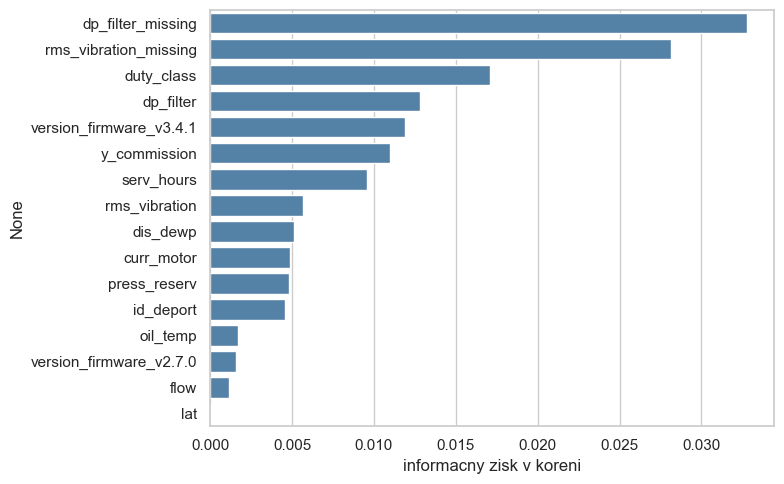

In [9]:
binovane = id3_pipeline()[:-1].fit_transform(train_X, train_y)
id3_pomocny = ID3Classifier()
zisk = pd.Series({c: id3_pomocny._gain(binovane[c].to_numpy(), train_y.to_numpy(), np.ones(len(train_y)))
                  for c in binovane.columns}).sort_values(ascending=False)
p = train_y.mean()
print("entropia ciela v koreni:", round(-(p * np.log2(p) + (1 - p) * np.log2(1 - p)), 4))

display(zisk.round(4).to_frame("informacny zisk").T)

plt.figure(figsize=(8, 5))
sns.barplot(x=zisk.values, y=zisk.index, color="steelblue")
plt.xlabel("informacny zisk v koreni"); plt.tight_layout(); plt.show()

Entropia cieľa v koreni je 0,529 bitu (asi 12 % porúch). Najviac ju znižujú príznaky chýbajúceho merania `dp_filter_missing` (0,033) a `rms_vibration_missing` (0,028), za nimi `duty_class` (0,017) a `dp_filter` (0,013). Poradie sa zhoduje s výberom atribútov z 2.2. Koreňom stromu bude `dp_filter_missing`.

Zisky sú v absolútnej hodnote malé. Žiadny atribút sám poruchu neurčí, preto strom potrebuje viac úrovní.

In [10]:
id3_zaklad = id3_pipeline().fit(train_X, train_y)      # cisty ID3 bez obmedzeni
strom = id3_zaklad.named_steps["id3"]
print("hlbka (vratane korena):", strom.depth_, "| uzly:", strom.n_nodes_, "| listy:", strom.n_leaves_)
print("\nprve dve urovne pod korenom:")
vypis_strom(strom, max_uroven=3, bin_cols=BIN_COLS)

hlbka (vratane korena): 13 | uzly: 4192 | listy: 2908

prve dve urovne pod korenom:
dp_filter_missing = 0  [n=10610, porucha=10%]
    rms_vibration_missing = 0  [n=10229, porucha=9%]
    rms_vibration_missing = 1  [n=381, porucha=49%]
dp_filter_missing = 1  [n=406, porucha=57%]
    rms_vibration_missing = 0  [n=374, porucha=53%]
    rms_vibration_missing = 1  [n=32, porucha=97%]


Čistý ID3 bez obmedzení narástol do hĺbky 13 (požiadavka zadania na hĺbku aspoň 2 vrátane koreňa je splnená) a má 4 192 uzlov, z toho 2 908 listov. Na 11 016 trénovacích riadkov to vychádza na menej ako 4 riadky na list, čo je prvý signál, že si strom pamätá jednotlivé merania.

Prvé úrovne sú pritom zmysluplné. Ak chýba `dp_filter`, podiel porúch je 57 % oproti 10 %, a ak chýbajú obe merania, až 97 % (32 riadkov). Platí predpoklad z fázy 2, že hodnota chýba skôr, než porucha nastane.

### Vyhodnotenie ID3

Porúch je asi 12 %, takže model "vždy bez poruchy" má accuracy 88 %, no je nepoužiteľný. Rozhodujeme preto podľa **recall**, **precision**, **F1**, **balanced accuracy**, **ROC-AUC** a **PR-AUC** - accuracy uvádzame len na porovnanie.

Hodnotíme 5-násobnou CV na trénovacej množine delenou podľa `id_unit` (`StratifiedGroupKFold`), pričom sa celá pipeline v každom foldu učí nanovo.

In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "balanced accuracy": "balanced_accuracy", "precision": "precision",
           "recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc", "PR-AUC": "average_precision"}

def cv_vysledky(model):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")        # precision = 0/0, ked model v niektorom kroku nepredikuje ziadnu poruchu
        s = cross_validate(model, train_X, train_y, groups=train_groups, cv=cv, scoring=SCORING,
                           return_train_score=True, n_jobs=-1)
    return pd.DataFrame({"train": {m: s["train_" + m].mean() for m in SCORING},
                         "validacia": {m: s["test_" + m].mean() for m in SCORING},
                         "validacia std": {m: s["test_" + m].std() for m in SCORING}})

def metriky(model, X, y):
    pred, proba = model.predict(X), model.predict_proba(X)[:, 1]
    return pd.Series({"accuracy": accuracy_score(y, pred), "balanced accuracy": balanced_accuracy_score(y, pred),
                      "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                      "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, proba),
                      "PR-AUC": average_precision_score(y, proba)})

vys_zaklad = cv_vysledky(id3_pipeline())
vys_zaklad["rozdiel"] = vys_zaklad["train"] - vys_zaklad["validacia"]
display(vys_zaklad.round(3))

,train,validacia,validacia std,rozdiel
accuracy,0.983,0.820,0.002,0.163
balanced accuracy,0.959,0.593,0.012,0.366
precision,0.930,0.270,0.013,0.660
recall,0.927,0.295,0.028,0.633
F1,0.929,0.282,0.019,0.647
ROC-AUC,0.962,0.609,0.011,0.353
PR-AUC,0.879,0.172,0.007,0.707


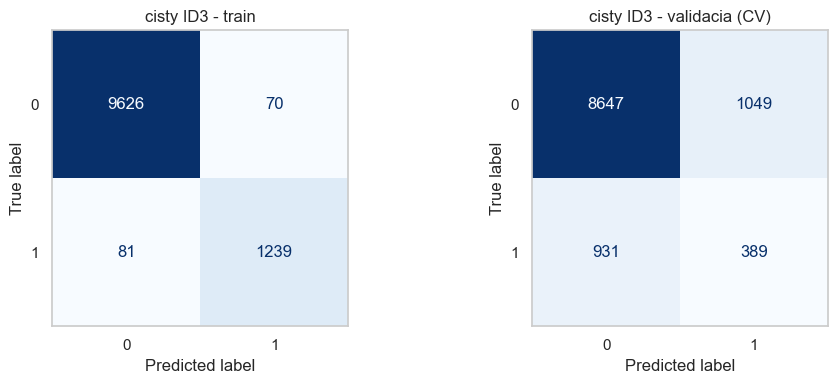

              precision    recall  f1-score   support

 bez poruchy      0.903     0.892     0.897      9696
     porucha      0.271     0.295     0.282      1320

    accuracy                          0.820     11016
   macro avg      0.587     0.593     0.590     11016
weighted avg      0.827     0.820     0.824     11016



In [12]:
# matica zamien z validacnych casti 
# kazdy riadok je predikovany modelom, ktory ho pri uceni nevidel
pred_val = cross_val_predict(id3_pipeline(), train_X, train_y, groups=train_groups, cv=cv, n_jobs=-1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(train_y, id3_zaklad.predict(train_X), ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("cisty ID3 - train")
ConfusionMatrixDisplay.from_predictions(train_y, pred_val, ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title("cisty ID3 - validacia (CV)")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()
print(classification_report(train_y, pred_val, target_names=["bez poruchy", "porucha"], digits=3))

**Vyhodnotenie čistého ID3.** Na trénovacích častiach vyzerá model takmer dokonale (F1 0,929; ROC-AUC 0,962), na validačných je slabý:

* zachytí iba 29,5 % porúch (recall) a z hlásených porúch je skutočných 27,0 % (precision), F1 = 0,282
* accuracy 0,820 je nižšia než 0,880, ktoré by dosiahol model bez jedinej hlásenej poruchy, takže o kvalite nič nehovorí
* ROC-AUC 0,609 je len o málo lepšie než náhodné zoradenie (0,5) a PR-AUC je len 0,172

Výsledky sú medzi piatimi časťami stabilné (smerodajná odchýlka F1 0,019), takže nejde o náhodu jedného delenia.

### Overfitting

**Má ID3 overfit?** Porovnávame skóre na trénovacích a validačných častiach krížovej validácie. Ak je model na dátach, ktoré videl, výrazne lepší než na nových, naučil sa šum a nie vzťahy. Zložitosť stromu riadime hĺbkou, preto pre každú hĺbku meriame obe skóre.

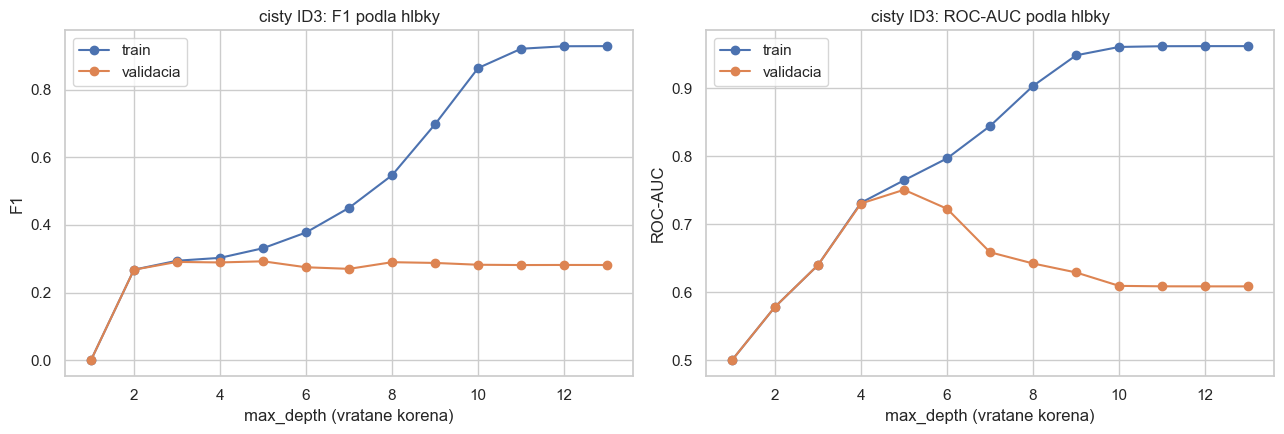

,F1 train,recall train,precision train,ROC-AUC train,F1 val,recall val,precision val,ROC-AUC val
max_depth,,,,,,,,
1,0.000,0.000,0.000,0.500,0.000,0.000,0.000,0.500
2,0.268,0.175,0.569,0.578,0.268,0.175,0.569,0.578
3,0.294,0.204,0.563,0.640,0.291,0.201,0.555,0.640
4,0.303,0.202,0.631,0.732,0.289,0.197,0.565,0.731
5,0.331,0.219,0.693,0.765,0.292,0.196,0.584,0.751
6,0.378,0.248,0.793,0.797,0.275,0.182,0.565,0.723
7,0.451,0.300,0.908,0.845,0.270,0.182,0.530,0.659
8,0.547,0.399,0.870,0.904,0.290,0.217,0.439,0.642
9,0.698,0.577,0.882,0.949,0.288,0.253,0.334,0.629


In [13]:
hlbky = list(range(1, 14))      # neobmedzeny strom ma hlbku 13, cize 13 = bez obmedzenia
riadky = []
for vahy in [None, "balanced"]:
    for h in hlbky:
        v = cv_vysledky(id3_pipeline(max_depth=h, class_weight=vahy))
        riadky.append({"class_weight": str(vahy), "max_depth": h,
                       **{f"{m} train": v.loc[m, "train"] for m in ["F1", "recall", "precision", "ROC-AUC"]},
                       **{f"{m} val": v.loc[m, "validacia"] for m in ["F1", "recall", "precision", "ROC-AUC"]}})
krivka = pd.DataFrame(riadky)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
k = krivka[krivka["class_weight"] == "None"]
for a, m in zip(ax, ["F1", "ROC-AUC"]):
    a.plot(k["max_depth"], k[f"{m} train"], marker="o", label="train")
    a.plot(k["max_depth"], k[f"{m} val"], marker="o", label="validacia")
    a.set_title(f"cisty ID3: {m} podla hlbky"); a.set_xlabel("max_depth (vratane korena)")
    a.set_ylabel(m); a.legend()
plt.tight_layout(); plt.show()
display(k.set_index("max_depth").drop(columns="class_weight").round(3))


**Áno, čistý ID3 má overfit.**

* Do hĺbky 5 idú obe krivky spolu (ROC-AUC 0,765 na train a 0,751 na validácii).
* Od hĺbky 6 trénovacie skóre ďalej rastie (F1 až 0,93, ROC-AUC 0,96), no validačné ROC-AUC klesá z 0,751 na 0,609 a validačné F1 sa drží okolo 0,28. Každá ďalšia úroveň teda pridáva pravidlá, ktoré platia len pre trénovacie riadky.
* Pri neobmedzenom strome je rozdiel medzi train a validáciou 0,65 v F1 a 0,35 v ROC-AUC.

Opačný problém vidno pri hĺbke 1 a 2: model je príliš jednoduchý (ROC-AUC 0,50 a 0,58), čo je underfit. Vhodná zložitosť je teda niekde okolo hĺbky 5.

**Riešenie.** Používame dve úpravy:

1. **Predčasné zastavenie (pre-pruning)** - obmedzíme hĺbku (`max_depth`) a najmenší uzol, ktorý sa ešte smie deliť (`min_samples_split`). Strom tak nemôže vytvárať listy pre jednotlivé riadky.
2. **Váhy tried** (`class_weight="balanced"`) - samotné orezanie overfit odstráni, ale plytký strom s väčšinovým hlasovaním takmer nikdy nepredikuje poruchu. Váhy vyrovnajú obe triedy v entropii aj v listoch.

Porovnanie oboch variantov pri rovnakej hĺbke:

In [14]:
por = krivka[krivka["max_depth"].isin([3, 4, 5, 6])].pivot(index="max_depth", columns="class_weight",
                                                       values=["recall val", "precision val", "F1 val", "ROC-AUC val"])
display(por.round(3))

recall val          precision val          F1 val           \
class_weight       None balanced          None balanced   None balanced   
max_depth                                                                 
3                 0.201    0.317         0.555    0.531  0.291    0.396   
4                 0.197    0.739         0.565    0.202  0.289    0.318   
5                 0.196    0.652         0.584    0.251  0.292    0.362   
6                 0.182    0.552         0.565    0.268  0.275    0.361   

             ROC-AUC val           
class_weight        None balanced  
max_depth                          
3                  0.640    0.640  
4                  0.731    0.731  
5                  0.751    0.752  
6                  0.723    0.718

Váhy takmer nemenia zoradenie pozorovaní (ROC-AUC), menia rozhodnutie v listoch: pri hĺbke 5 stúpne recall z 0,196 na 0,652 a F1 z 0,292 na 0,362, precision klesne z 0,584 na 0,251. Pri prediktívnej údržbe je prehliadnutá porucha drahšia než falošný poplach, preto ďalej používame `class_weight="balanced"`.

Zostáva zvoliť `max_depth` a `min_samples_split`

In [15]:
riadky = []
for h in [3, 4, 5, 6, 7, 8, 10]:
    for mss in [2, 100, 200, 400]:
        v = cv_vysledky(id3_pipeline(max_depth=h, min_samples_split=mss, class_weight="balanced"))
        riadky.append({"max_depth": h, "min_samples_split": mss,
                       "ROC-AUC train": v.loc["ROC-AUC", "train"], "ROC-AUC val": v.loc["ROC-AUC", "validacia"],
                       "F1 train": v.loc["F1", "train"], "F1 val": v.loc["F1", "validacia"],
                       "recall val": v.loc["recall", "validacia"]})
mriezka = pd.DataFrame(riadky)
mriezka["rozdiel ROC-AUC"] = mriezka["ROC-AUC train"] - mriezka["ROC-AUC val"]
mriezka["rozdiel F1"] = mriezka["F1 train"] - mriezka["F1 val"]

# bez overfitu: train a validacia sa lisia najviac o 0,02, spomedzi nich najlepsie validacne ROC-AUC
bez_overfitu = mriezka[(mriezka["rozdiel ROC-AUC"] <= 0.02) & (mriezka["rozdiel F1"] <= 0.02)]
najlepsi = bez_overfitu.sort_values("ROC-AUC val", ascending=False, kind="stable").iloc[0]
display(mriezka.sort_values("ROC-AUC val", ascending=False).head(12).round(3))
print("vybrane nastavenie: max_depth =", int(najlepsi["max_depth"]), "| min_samples_split =", int(najlepsi["min_samples_split"]))


,max_depth,min_samples_split,ROC-AUC train,ROC-AUC val,F1 train,F1 val,recall val,rozdiel ROC-AUC,rozdiel F1
23,8,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
27,10,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
19,7,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
9,5,100,0.764,0.760,0.369,0.365,0.659,0.005,0.004
10,5,200,0.764,0.760,0.369,0.365,0.659,0.005,0.004
13,6,100,0.790,0.759,0.397,0.378,0.602,0.030,0.019
11,5,400,0.763,0.759,0.369,0.365,0.659,0.004,0.004
14,6,200,0.789,0.759,0.397,0.378,0.602,0.030,0.019
15,6,400,0.786,0.758,0.394,0.371,0.592,0.027,0.022
22,8,200,0.808,0.755,0.393,0.361,0.656,0.054,0.032


vybrane nastavenie: max_depth = 5 | min_samples_split = 100


Validačné ROC-AUC 0,760 dosahuje viac nastavení. Stromy s hĺbkou 7 až 10 a `min_samples_split = 400` ho dosahujú s rozdielom 0,033 medzi train a validáciou, strom s hĺbkou 5 a `min_samples_split = 100` s rozdielom 0,005. Volíme preto jednoduchší: **`max_depth = 5`, `min_samples_split = 100`, `class_weight = "balanced"`**.

In [16]:
PARAMS = dict(max_depth=int(najlepsi["max_depth"]), min_samples_split=int(najlepsi["min_samples_split"]),
              class_weight="balanced")
vys_final = cv_vysledky(id3_pipeline(**PARAMS))
vys_final["rozdiel"] = vys_final["train"] - vys_final["validacia"]

porovnanie = pd.concat({"cisty ID3": vys_zaklad[["train", "validacia", "rozdiel"]],
                        "upraveny ID3": vys_final[["train", "validacia", "rozdiel"]]}, axis=1)
display(porovnanie.round(3))

cisty ID3                   upraveny ID3                  
                      train validacia rozdiel        train validacia rozdiel
accuracy              0.983     0.820   0.163        0.727     0.725   0.002
balanced accuracy     0.959     0.593   0.366        0.700     0.697   0.003
precision             0.930     0.270   0.660        0.256     0.253   0.003
recall                0.927     0.295   0.633        0.663     0.659   0.004
F1                    0.929     0.282   0.647        0.369     0.365   0.004
ROC-AUC               0.962     0.609   0.353        0.764     0.760   0.005
PR-AUC                0.879     0.172   0.707        0.381     0.364   0.016

**Záverečné overenie na testovacej množine.** Upravený ID3 učíme na celej trénovacej množine a prvýkrát ho použijeme na testovacej, ktorú model ani výber parametrov nevideli.

hlbka (vratane korena): 5 | uzly: 41 | listy: 29


,cisty ID3 - train,cisty ID3 - test,upraveny ID3 - train,upraveny ID3 - test
accuracy,0.986,0.830,0.715,0.717
balanced accuracy,0.966,0.618,0.700,0.723
precision,0.947,0.306,0.248,0.257
recall,0.939,0.339,0.680,0.731
F1,0.943,0.322,0.364,0.380
ROC-AUC,0.968,0.635,0.764,0.788
PR-AUC,0.901,0.194,0.388,0.418


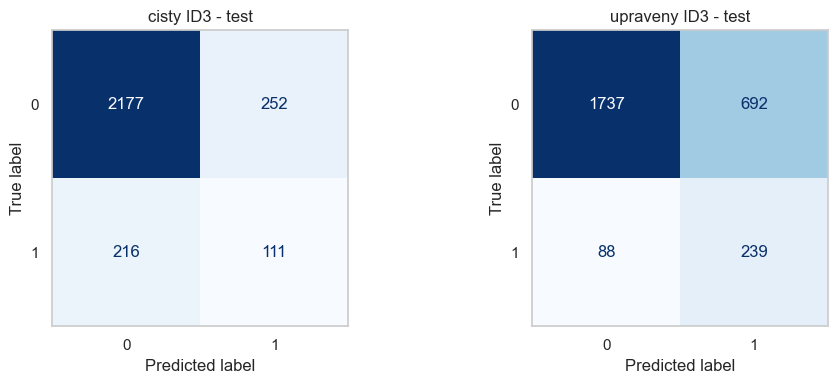

In [17]:
id3_final = id3_pipeline(**PARAMS).fit(train_X, train_y)
strom = id3_final.named_steps["id3"]
print("hlbka (vratane korena):", strom.depth_, "| uzly:", strom.n_nodes_, "| listy:", strom.n_leaves_)

tab = pd.DataFrame({"cisty ID3 - train": metriky(id3_zaklad, train_X, train_y),
                    "cisty ID3 - test": metriky(id3_zaklad, test_X, test_y),
                    "upraveny ID3 - train": metriky(id3_final, train_X, train_y),
                    "upraveny ID3 - test": metriky(id3_final, test_X, test_y)})
display(tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(test_y, id3_zaklad.predict(test_X), ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("cisty ID3 - test")
ConfusionMatrixDisplay.from_predictions(test_y, id3_final.predict(test_X), ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title("upraveny ID3 - test")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()

In [18]:
print("pravidla upraveneho ID3 (prve tri urovne pod korenom):")
vypis_strom(strom, max_uroven=4, bin_cols=BIN_COLS)

pravidla upraveneho ID3 (prve tri urovne pod korenom):
dp_filter_missing = 0  [n=10610, porucha=10%]
    rms_vibration_missing = 0  [n=10229, porucha=9%]
        duty_class = 1  [n=4040, porucha=14%]
        duty_class = 2  [n=3639, porucha=7%]
        duty_class = 3  [n=2550, porucha=4%]
    rms_vibration_missing = 1  [n=381, porucha=49%]
        serv_hours = Q1  [n=71, porucha=34%] -> porucha=1
        serv_hours = Q2  [n=86, porucha=41%] -> porucha=1
        serv_hours = Q3  [n=111, porucha=50%]
        serv_hours = Q4  [n=113, porucha=64%]
dp_filter_missing = 1  [n=406, porucha=57%]
    rms_vibration_missing = 0  [n=374, porucha=53%]
        y_commission = Q1  [n=93, porucha=69%] -> porucha=1
        y_commission = Q2  [n=91, porucha=51%] -> porucha=1
        y_commission = Q3  [n=70, porucha=50%] -> porucha=1
        y_commission = Q4  [n=120, porucha=46%]
    rms_vibration_missing = 1  [n=32, porucha=97%] -> porucha=1


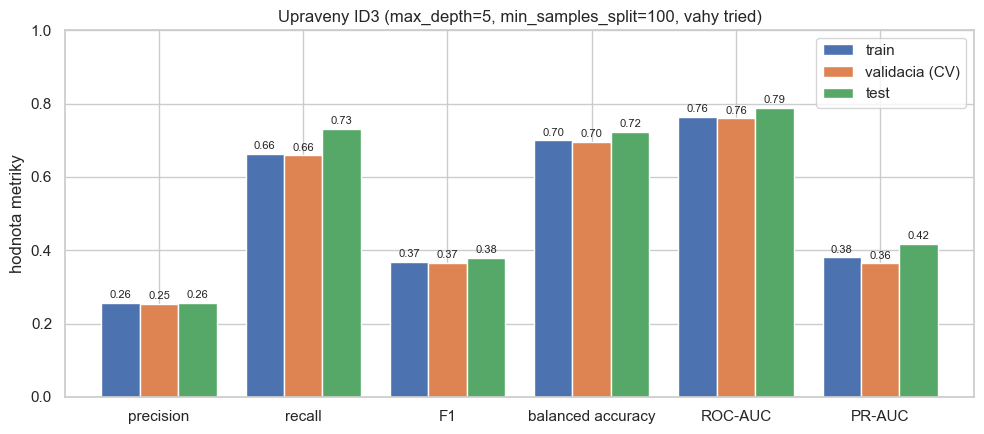

In [19]:
metriky_graf = ["precision", "recall", "F1", "balanced accuracy", "ROC-AUC", "PR-AUC"]
vysledky_graf = pd.DataFrame({
    "train": vys_final.loc[metriky_graf, "train"],
    "validacia (CV)": vys_final.loc[metriky_graf, "validacia"],
    "test": tab.loc[metriky_graf, "upraveny ID3 - test"],
})

ax = vysledky_graf.plot(kind="bar", figsize=(10, 4.5), width=0.8, edgecolor="white")
for kontajner in ax.containers:
    ax.bar_label(kontajner, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1)
ax.set_ylabel("hodnota metriky")
ax.set_title("Upraveny ID3 (max_depth=5, min_samples_split=100, vahy tried)")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

Pri váhach tried list hlási poruchu, ak je v ňom podiel porúch vyšší než v celých dátach (asi 12 %), preto aj list s 34 % porúch dáva `fail=1`.

### Záver k 3.1

| | čistý ID3 | upravený ID3 |
|---|---|---|
| nastavenie | bez obmedzení | `max_depth=5`, `min_samples_split=100`, `class_weight="balanced"` |
| veľkosť | hĺbka 13, 4 192 uzlov | hĺbka 5, 41 uzlov |
| F1 train / test | 0,943 / 0,322 | 0,364 / 0,380 |
| ROC-AUC train / test | 0,968 / 0,635 | 0,764 / 0,788 |
| recall train / test | 0,939 / 0,339 | 0,680 / 0,731 |

* Implementovali sme ID3 (entropia, informačný zisk, kvartily) a hodnotili ho metrikami pre nevyvážené triedy v CV delenej podľa jednotiek.
* Čistý ID3 silno overfituje (F1 0,943 na train, 0,322 na teste). Po obmedzení hĺbky a uzla je strom stokrát menší a train, validácia aj test sedia (F1 0,364 / 0,365 / 0,380), takže overfit je odstránený a nejde ani o underfit.

**Obmedzenie:** precision je 0,26 (tri zo štyroch hlásení sú falošné poplachy), čo je cena za recall 0,73 pri jednoduchom strome. V 3.2 porovnáme ID3 so `scikit-learn`.

## 3.2 Trénovanie a vyhodnotenie klasifikátorov strojového učenia

Random forest a logistickú regresiu porovnávame s ID3 z časti 3.1. Používame rovnaké predspracovanie a päť validačných foldov podľa `id_unit`.

Poruchy tvoria asi 12 % dát, preto nastavenia vyberáme podľa priemernej validačnej AP (average precision). Testovaciu množinu použijeme až po výbere nastavení.

### Stromový algoritmus - Random Forest

Random forest kombinuje predikcie 160 stromov. Každý strom sa učí na náhodnej vzorke dát s opakovaním a pri delení zvažuje náhodný výber atribútov.

Porovnávame rôzne hĺbky stromov a minimálne počty záznamov v liste. Váhami tried zohľadňujeme, že poruchy sú zriedkavé.

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.tree import plot_tree
from IPython.display import Markdown

def sk_pipeline(model):
    return Pipeline([("prep", build_pipeline()), ("model", model)])

forest_name = "Random Forest"
logreg_name = "Logisticka regresia"
id3_name = "ID3 upraveny"

forest_candidates = {
    (depth, leaf): sk_pipeline(RandomForestClassifier(
        n_estimators=160,
        max_depth=depth,
        min_samples_leaf=leaf,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
    ))
    for depth, leaf in [(4, 40), (7, 40), (7, 15), (10, 15)]
}
forest_cv = {params: cv_vysledky(model) for params, model in forest_candidates.items()}
forest_table = pd.DataFrame([
    {"max_depth": depth, "min_samples_leaf": leaf,
     "AP trening": scores.loc["PR-AUC", "train"],
     "AP validacia": scores.loc["PR-AUC", "validacia"],
     "F1 validacia": scores.loc["F1", "validacia"]}
    for (depth, leaf), scores in forest_cv.items()
]).set_index(["max_depth", "min_samples_leaf"]).sort_values("AP validacia", ascending=False, kind="stable")
best_forest = forest_table.index[0]
final_forest = forest_candidates[best_forest]
display(forest_table.round(3))
print(f"Vybrany les: max_depth={best_forest[0]}, min_samples_leaf={best_forest[1]}")

AP trening  AP validacia  F1 validacia
max_depth min_samples_leaf                                        
10        15                     0.649         0.451         0.461
7         15                     0.560         0.449         0.442
          40                     0.531         0.448         0.433
4         40                     0.465         0.437         0.401

Vybrany les: max_depth=10, min_samples_leaf=15


### Nestromový algoritmus — logistická regresia

Logistická regresia vytvára lineárnu kombináciu predspracovaných atribútov a pomocou logistickej funkcie ju prevádza na skóre poruchy. Hodnota `C` riadi silu regularizácie (menšie `C` znamená silnejšiu regularizáciu). Pri trénovaní používame vyvážené váhy tried.

In [21]:
logreg_candidates = {
    c: sk_pipeline(LogisticRegression(C=c, class_weight="balanced", max_iter=2000))
    for c in [0.01, 0.1, 1, 10]
}
logreg_cv = {c: cv_vysledky(model) for c, model in logreg_candidates.items()}
logreg_table = pd.DataFrame([
    {"C": c, "AP trening": scores.loc["PR-AUC", "train"],
     "AP validacia": scores.loc["PR-AUC", "validacia"],
     "F1 validacia": scores.loc["F1", "validacia"]}
    for c, scores in logreg_cv.items()
]).set_index("C").sort_values("AP validacia", ascending=False, kind="stable")
best_c = logreg_table.index[0]
final_logreg = logreg_candidates[best_c]
display(logreg_table.round(3))
print(f"Vybrana logisticka regresia: C={best_c:g}")

,AP trening,AP validacia,F1 validacia
C,,,
0.10,0.488,0.487,0.415
1.00,0.486,0.486,0.419
10.00,0.486,0.486,0.419
0.01,0.474,0.473,0.398


Vybrana logisticka regresia: C=0.1


### Porovnanie s ID3

Uvádzame priemery na validačných foldoch a smerodajnú odchýlku AP naprieč foldmi. Rozdiely medzi trénovacím a validačným skóre ukazujú, ako lepšie model funguje na dátach, na ktorých sa učil. Do tabuľky zahŕňame aj čistý ID3, aby bolo vidieť vplyv jeho obmedzenia z časti 3.1.

In [22]:
vys_cv = {"ID3 cisty": vys_zaklad, id3_name: vys_final,
          forest_name: forest_cv[best_forest], logreg_name: logreg_cv[best_c]}
cv_tab = pd.DataFrame({name: scores["validacia"] for name, scores in vys_cv.items()})
cv_std = pd.DataFrame({
    name: {"AP - smerodajna odchylka validacie": scores.loc["PR-AUC", "validacia std"]}
    for name, scores in vys_cv.items()
})
cv_gap = pd.DataFrame({
    name: (scores["train"] - scores["validacia"]).loc[["F1", "ROC-AUC", "PR-AUC"]]
    for name, scores in vys_cv.items()
})
cv_gap.index = [f"Rozdiel trening - validacia ({metric})" for metric in cv_gap.index]
display(pd.concat([cv_tab.rename(index={"PR-AUC": "AP"}), cv_std, cv_gap]).round(3))

for model in (final_forest, final_logreg):
    model.fit(train_X, train_y)
test_modely = {"ID3 cisty": id3_zaklad, id3_name: id3_final,
               forest_name: final_forest, logreg_name: final_logreg}
test_tab = pd.DataFrame({name: metriky(model, test_X, test_y) for name, model in test_modely.items()})
print("Testovacia mnozina")
display(test_tab.rename(index={"PR-AUC": "AP"}).round(3))

,ID3 cisty,ID3 upraveny,Random Forest,Logisticka regresia
accuracy,0.820,0.725,0.846,0.764
balanced accuracy,0.593,0.697,0.718,0.736
precision,0.270,0.253,0.398,0.296
recall,0.295,0.659,0.549,0.699
F1,0.282,0.365,0.461,0.415
ROC-AUC,0.609,0.760,0.795,0.807
AP,0.172,0.364,0.451,0.487
AP - smerodajna odchylka validacie,0.007,0.030,0.027,0.036
Rozdiel trening - validacia (F1),0.647,0.004,0.123,-0.001
Rozdiel trening - validacia (ROC-AUC),0.353,0.005,0.129,0.003


Testovacia mnozina


,ID3 cisty,ID3 upraveny,Random Forest,Logisticka regresia
accuracy,0.830,0.717,0.844,0.765
balanced accuracy,0.618,0.723,0.747,0.756
precision,0.306,0.257,0.398,0.301
recall,0.339,0.731,0.621,0.743
F1,0.322,0.380,0.485,0.429
ROC-AUC,0.635,0.788,0.819,0.837
AP,0.194,0.418,0.507,0.520


### Vizualizácia natrénovaných pravidiel

Diagram ukazuje prvé tri úrovne prvého stromu v natrénovanom lese. Prahy sú v jednotkách po predspracovaní vstupov. Ľavá vetva zodpovedá splnenej podmienke v uzle. Zobrazený strom je jeden z prispievateľov k výslednému skóre, ktoré vzniká priemerovaním odhadov celého lesa.

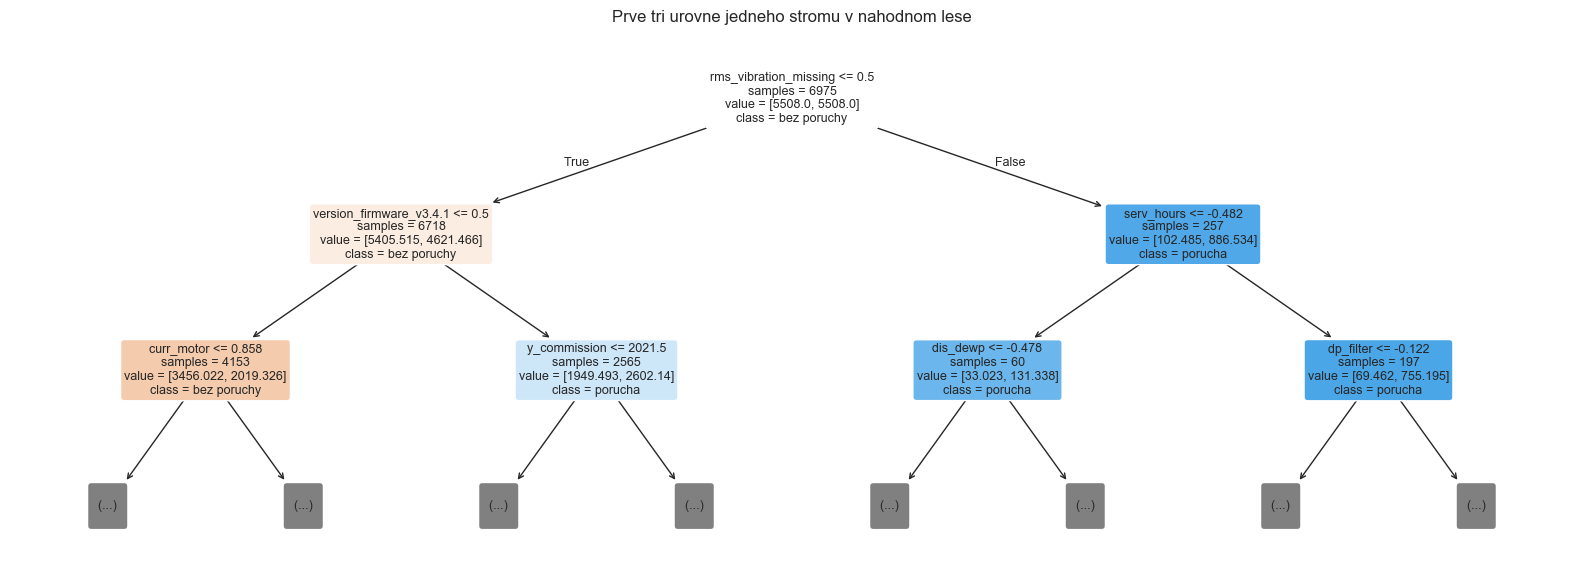

In [23]:
feature_names = final_forest.named_steps["prep"].get_feature_names_out()
first_tree = final_forest.named_steps["model"].estimators_[0]

fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(first_tree, feature_names=list(feature_names),
          class_names=["bez poruchy", "porucha"], max_depth=2,
          filled=True, rounded=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("Prve tri urovne jedneho stromu v nahodnom lese")
plt.tight_layout()
plt.show()

### Vyhodnotenie na testovacej množine

Matice zámen zobrazujú predvolené rozhodnutia modelov. Krivky ROC a precision–recall ukazujú, ako sa hodnotenie mení s prahom. Prerušovaná čiara v grafe precision–recall označuje podiel porúch v testovacej množine.

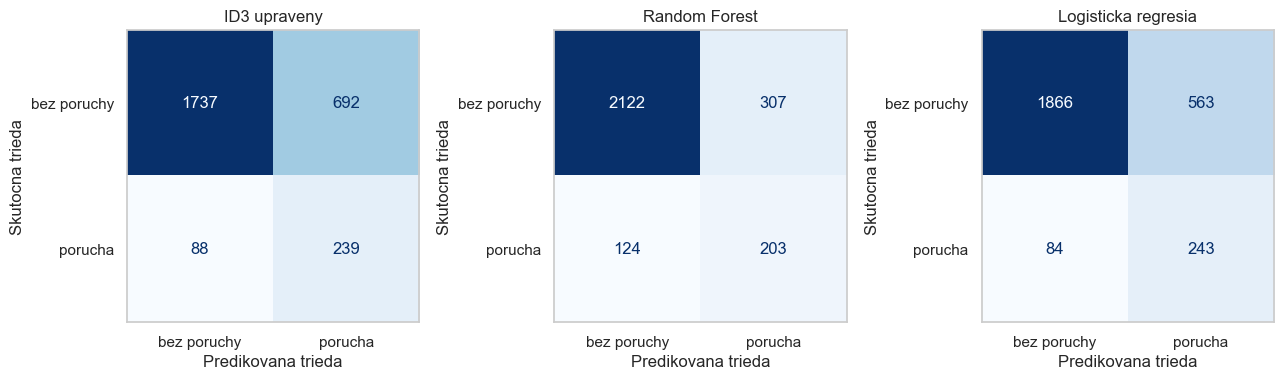

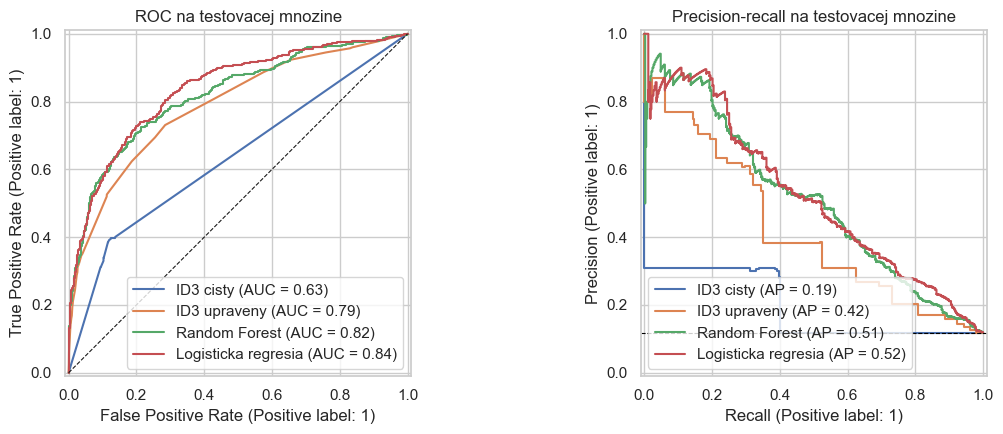

In [24]:
names = [id3_name, forest_name, logreg_name]
test_pred = {name: model.predict(test_X) for name, model in test_modely.items()}
test_proba = {name: model.predict_proba(test_X)[:, 1] for name, model in test_modely.items()}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, names):
    ConfusionMatrixDisplay.from_predictions(
        test_y, test_pred[name], display_labels=["bez poruchy", "porucha"],
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set(title=name, xlabel="Predikovana trieda", ylabel="Skutocna trieda")
    ax.grid(False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, scores in test_proba.items():
    RocCurveDisplay.from_predictions(test_y, scores, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(test_y, scores, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("ROC na testovacej mnozine")
axes[1].axhline(test_y.mean(), color="black", linestyle="--", linewidth=0.8)
axes[1].set_title("Precision-recall na testovacej mnozine")
plt.tight_layout()
plt.show()

### Záver k 3.2

In [ ]:
modely = [id3_name, forest_name, logreg_name]

zhrnutie_32 = pd.DataFrame({
    "Validacna AP": cv_tab.loc["PR-AUC", modely],
    "Rozdiel AP (trening − validacia)": cv_gap.loc[
        "Rozdiel trening - validacia (PR-AUC)", modely
    ],
    "Testovacie F1": test_tab.loc["F1", modely],
    "Recall na teste": test_tab.loc["recall", modely],
    "Precision na teste": test_tab.loc["precision", modely],
})

display(zhrnutie_32.style.format({
    "Validacná AP": "{:.3f}",
    "Rozdiel AP (tréning − validacia)": "{:.3f}",
    "Testovacie F1": "{:.3f}",
    "Recall na teste": "{:.0%}",
    "Precision na teste": "{:.0%}",
}, decimal=","))

,Validacná AP,Rozdiel AP (tréning − validácia),Testovacie F1,Recall na teste,Precision na teste
ID3 upraveny,"0,364","0,016354","0,380",73%,26%
Random Forest,"0,451","0,197904","0,485",62%,40%
Logisticka regresia,"0,487","0,000637","0,429",74%,30%


- Logistická regresia mala najvyššiu validačnú AP (0,487). Random forest dosiahol 0,451 a upravený ID3 0,364.
- Random forest mal najvyššie F1 na teste (0,485). Rozdiel medzi tréningovou a validačnou AP (0,198) naznačuje preučenie.
- Logistická regresia zachytila viac porúch (74 % oproti 62 %). Random forest mal vyšší podiel správnych poplachov (40 % oproti 30 %).

Pri prediktívnej údržbe treba pri interpretácii výsledkov overiť, či príznaky chýbajúcich meraní poznáme už v okamihu predikcie.